# Lab 2 – Chương 2: Toán tử điểm ảnh & Lọc không gian (Tổng kết)

Notebook tổng hợp ngắn gọn các thực nghiệm từ `01`–`06` trong `/notebook`, trả lời trực tiếp từng yêu cầu của đề bài:

| Phần | Yêu cầu | Mục |
|---|---|---|
| **I. Toán tử điểm ảnh** | Độ sáng · Tương phản · Âm bản · Cắt ngưỡng | 1–4 |
| **II. Lọc tuyến tính** | Mean · Gaussian · Làm sắc nét | 5–7 |
| **III. Nâng cao** | Sobel/Prewitt · Kernel tự thiết kế · So sánh các bộ lọc · Lọc phi tuyến (median, bilateral) | 8–11 |

Ảnh dùng: `data/input/` (`02_chelsea` – màu, `01_astronaut` – màu, `04_camera` – xám, `05_coins`, `18_page`).

In [1]:
from pathlib import Path
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

# Tự tìm thư mục data/input (chạy từ lab_2/ hoặc lab_2/notebook/ đều được)
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "input").is_dir())
IN = ROOT / "data" / "input"

def load(name, gray=False):
    p = IN / name
    if not p.is_file():
        raise FileNotFoundError(f"Không thấy {p}\nCác file hiện có: {sorted(x.name for x in IN.glob('*.png'))[:5]} ...")
    # np.fromfile + imdecode: đọc được cả đường dẫn Unicode/tiếng Việt trên Windows (cv2.imread thì không)
    data = np.fromfile(str(p), dtype=np.uint8)
    img = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Không giải mã được {p}")
    return img

def show(imgs, titles, cols=4, size=3.6):
    rows = -(-len(imgs) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, im, t in zip(axes.ravel(), imgs, titles):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255) if im.ndim == 2 else ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(t, fontsize=10)
    plt.tight_layout(); plt.show()

cat   = load("02_chelsea.png")             # ảnh màu
astro = load("01_astronaut.png")           # ảnh màu
cam   = load("04_camera.png", gray=True)   # ảnh xám
print("Thư mục ảnh:", IN)
print("chelsea", cat.shape, "| astronaut", astro.shape, "| camera", cam.shape)

Thư mục ảnh: c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_2\data\input
chelsea (300, 451, 3) | astronaut (512, 512, 3) | camera (512, 512)


# I. Toán tử điểm ảnh

## 1. Thay đổi độ sáng
$g(x,y)=\mathrm{clip}(f(x,y)+\beta,\,0,\,255)$ — cộng/trừ một hằng số cho **mọi** điểm ảnh.

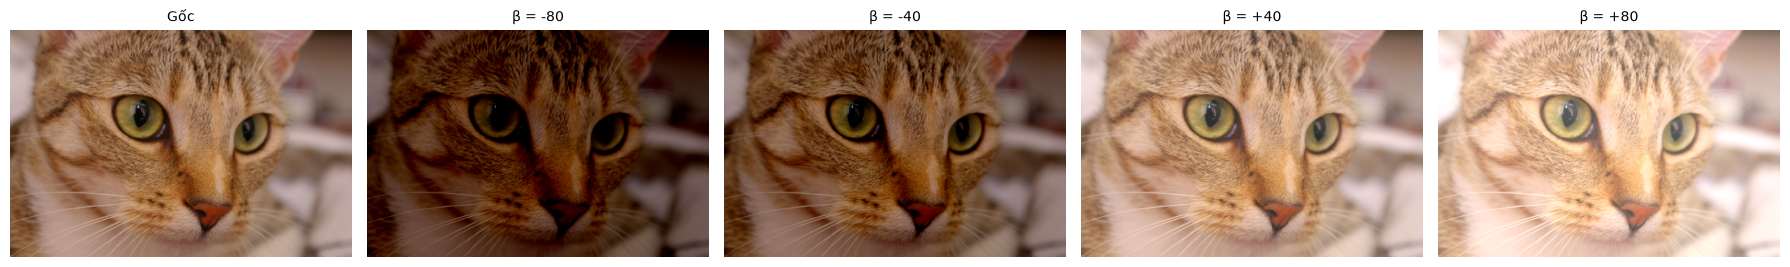

In [2]:
def brightness(img, beta):
    return np.clip(img.astype(np.int16) + beta, 0, 255).astype(np.uint8)

betas = [-80, -40, 40, 80]
show([cat] + [brightness(cat, b) for b in betas], ["Gốc"] + [f"β = {b:+d}" for b in betas], cols=5)

## 2. Thay đổi độ tương phản
$g(x,y)=\mathrm{clip}(\alpha\,(f(x,y)-127.5)+127.5,\,0,\,255)$ — nhân với hằng số $\alpha$ quanh mức xám giữa
($\alpha<1$ giảm, $\alpha>1$ tăng tương phản).

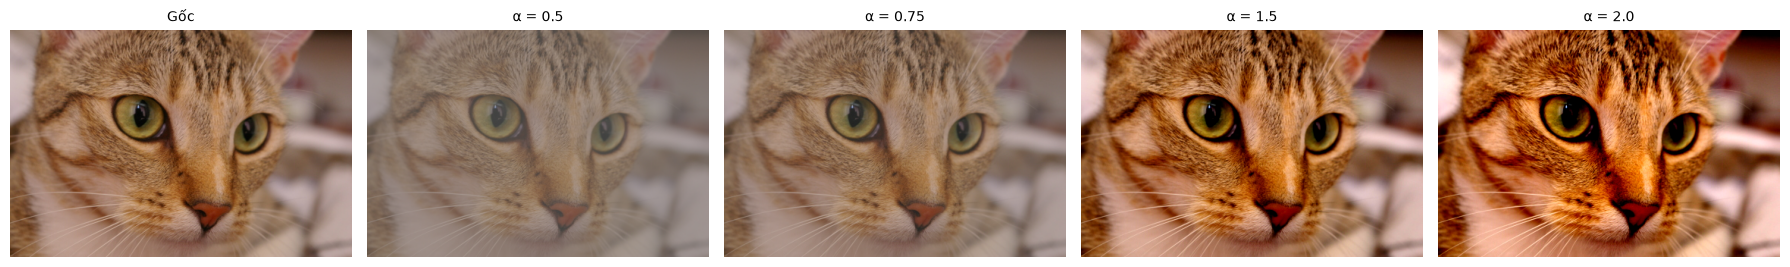

pixel: [  0  10 100 200 250] | +30 không clip: [ 30  40 130 230 280] | +30 có clip: [ 30  40 130 230 255]


In [3]:
def contrast(img, alpha):
    return np.clip((img.astype(np.float32) - 127.5) * alpha + 127.5, 0, 255).astype(np.uint8)

alphas = [0.5, 0.75, 1.5, 2.0]
show([cat] + [contrast(cat, a) for a in alphas], ["Gốc"] + [f"α = {a}" for a in alphas], cols=5)

# Clipping: giá trị vượt [0,255] bị dồn về biên -> mất chi tiết vùng quá sáng/tối
px = np.array([0, 10, 100, 200, 250])
print("pixel:", px, "| +30 không clip:", px + 30, "| +30 có clip:", np.clip(px + 30, 0, 255))

## 3. Biến đổi âm bản
$s = 255 - r$ (đảo cả 3 kênh với ảnh màu).

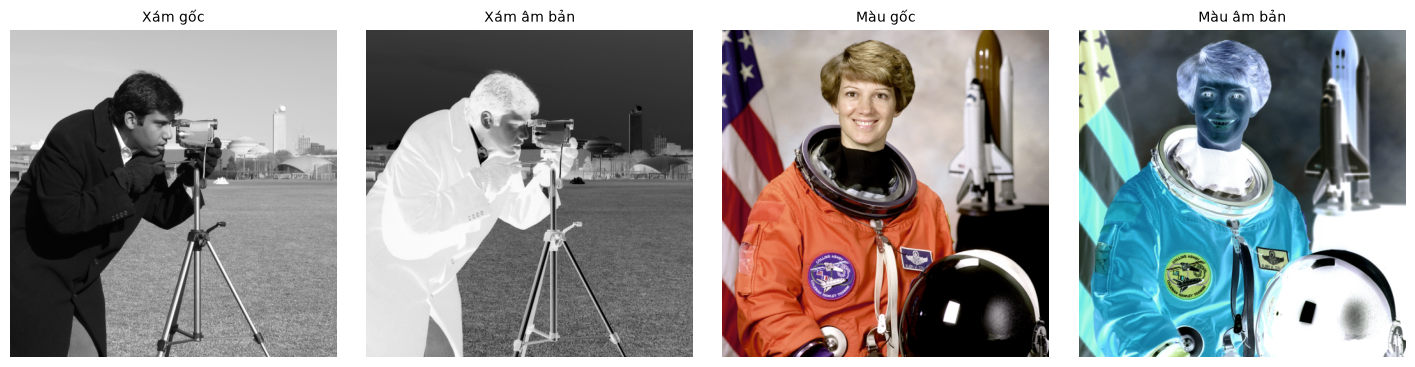

In [4]:
negative = lambda img: 255 - img
show([cam, negative(cam), astro, negative(astro)],
     ["Xám gốc", "Xám âm bản", "Màu gốc", "Màu âm bản"])

## 4. Cắt ngưỡng (nhị phân hóa)
$g=255$ nếu $f\ge T$, ngược lại $g=0$. Ảnh màu được chuyển sang xám trước khi cắt ngưỡng.

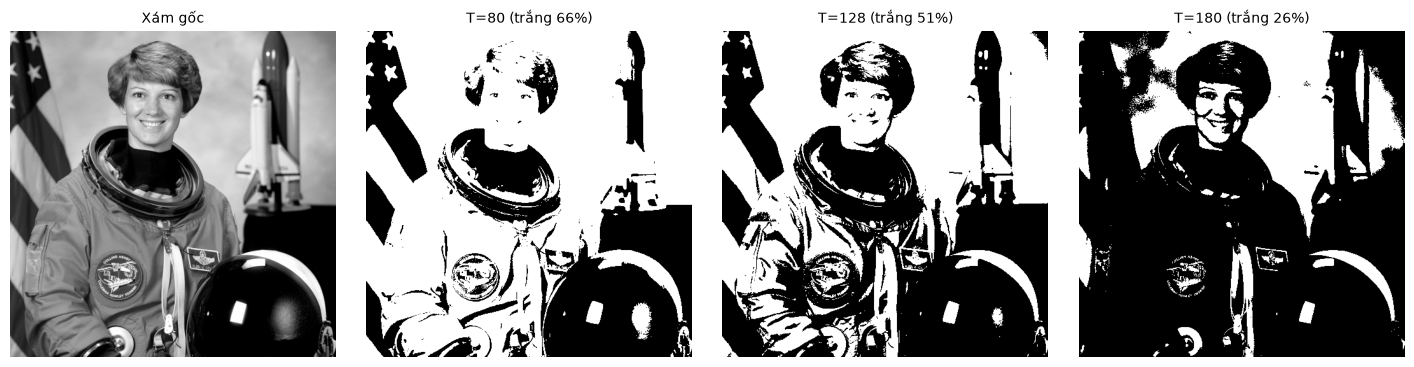

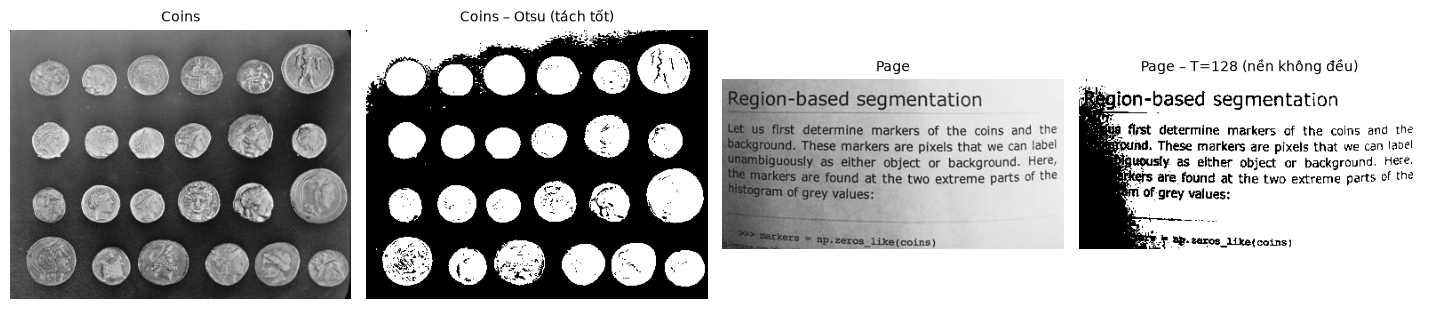

In [5]:
gray_astro = cv2.cvtColor(astro, cv2.COLOR_BGR2GRAY)
Ts = [80, 128, 180]
bins = [(gray_astro >= T).astype(np.uint8) * 255 for T in Ts]
show([gray_astro] + bins, ["Xám gốc"] + [f"T={T} (trắng {(b > 0).mean():.0%})" for T, b in zip(Ts, bins)])

# Hạn chế của ngưỡng toàn cục: ảnh tài liệu chiếu sáng không đều
page = load("18_page.png", gray=True); coins = load("05_coins.png", gray=True)
_, otsu_c = cv2.threshold(coins, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
show([coins, otsu_c, page, (page >= 128).astype(np.uint8) * 255],
     ["Coins", "Coins – Otsu (tách tốt)", "Page", "Page – T=128 (nền không đều)"])

# II. Lọc tuyến tính

## 5. Lọc trung bình (Mean / Box)
Kernel đồng đều $K=\frac{1}{k^2}\mathbf{1}$. Kiểm chứng tích chập tự cài đặt khớp `cv2`.

Sai khác lớn nhất manual vs cv2.blur: 0


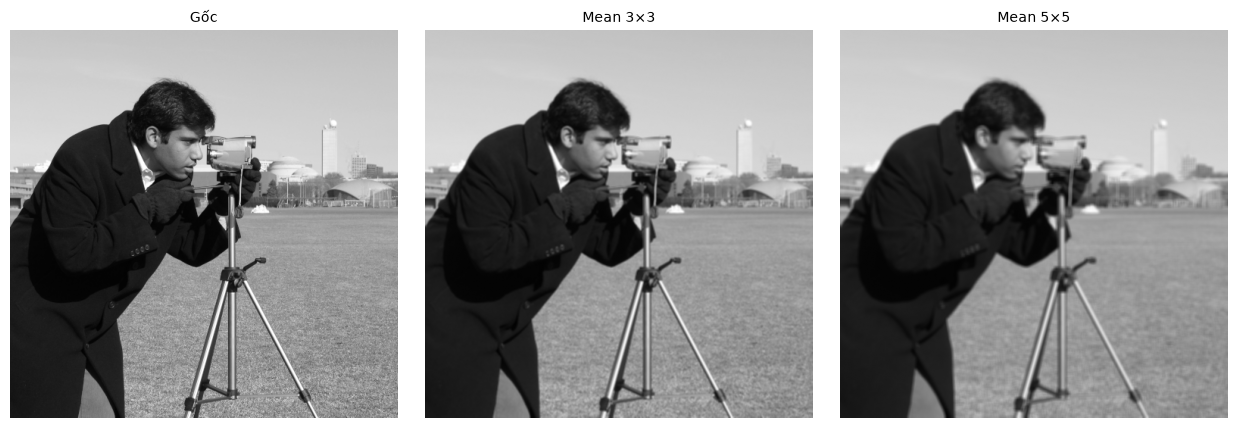

In [6]:
def conv2d(img, k):
    """Tích chập/tương quan 2D thủ công (padding reflect) cho ảnh xám."""
    r = k.shape[0] // 2
    p = np.pad(img.astype(np.float32), r, mode="reflect")
    out = np.zeros(img.shape, np.float32)
    for i in range(k.shape[0]):
        for j in range(k.shape[1]):
            out += k[i, j] * p[i:i + img.shape[0], j:j + img.shape[1]]
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)

mean3 = np.full((3, 3), 1 / 9, np.float32)
print("Sai khác lớn nhất manual vs cv2.blur:", np.abs(conv2d(cam, mean3).astype(int) - cv2.blur(cam, (3, 3)).astype(int)).max())

m3, m5 = cv2.blur(cam, (3, 3)), cv2.blur(cam, (5, 5))
show([cam, m3, m5], ["Gốc", "Mean 3×3", "Mean 5×5"], cols=3, size=4.2)

## 6. Lọc Gaussian
Trọng số giảm theo khoảng cách tới tâm: $K\propto e^{-r^2/2\sigma^2}$ → mờ tự nhiên hơn, ít nhòe khối so với Mean.

Kernel Gaussian 3×3:
 [[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]]


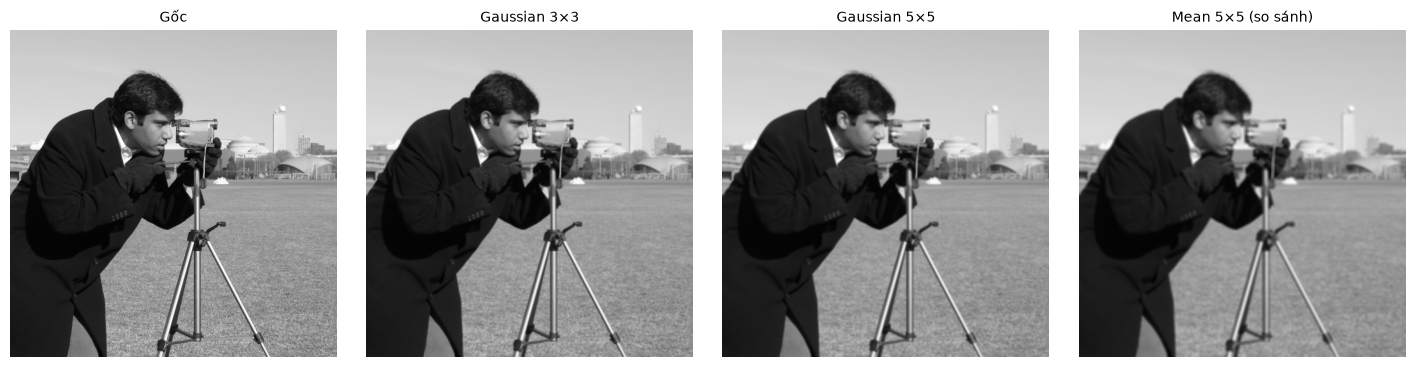

,Bộ lọc,PSNR (dB),SSIM
0,Ảnh nhiễu,22.402,0.368
1,Mean 3×3,27.392,0.642
2,Mean 5×5,26.175,0.687
3,Gaussian 3×3,28.020,0.647
4,Gaussian 5×5,27.838,0.702


In [7]:
g3, g5 = cv2.GaussianBlur(cam, (3, 3), 0), cv2.GaussianBlur(cam, (5, 5), 0)
print("Kernel Gaussian 3×3:\n", np.round(cv2.getGaussianKernel(3, 0) @ cv2.getGaussianKernel(3, 0).T, 4))
show([cam, g3, g5, m5], ["Gốc", "Gaussian 3×3", "Gaussian 5×5", "Mean 5×5 (so sánh)"])

# Định lượng khử nhiễu Gaussian (σ=20): so với ảnh sạch
rng = np.random.default_rng(42)
noisy_g = np.clip(cam + rng.normal(0, 20, cam.shape), 0, 255).astype(np.uint8)
rows = []
for name, im in [("Ảnh nhiễu", noisy_g), ("Mean 3×3", cv2.blur(noisy_g, (3, 3))), ("Mean 5×5", cv2.blur(noisy_g, (5, 5))),
                 ("Gaussian 3×3", cv2.GaussianBlur(noisy_g, (3, 3), 0)), ("Gaussian 5×5", cv2.GaussianBlur(noisy_g, (5, 5), 0))]:
    rows.append({"Bộ lọc": name, "PSNR (dB)": psnr(cam, im), "SSIM": ssim(cam, im)})
pd.DataFrame(rows).round(3)

## 7. Làm sắc nét
Kernel có hệ số dương ở tâm, âm ở lân cận → tăng độ chênh lệch cục bộ, nổi cạnh (nhưng **cũng khuếch đại nhiễu**).

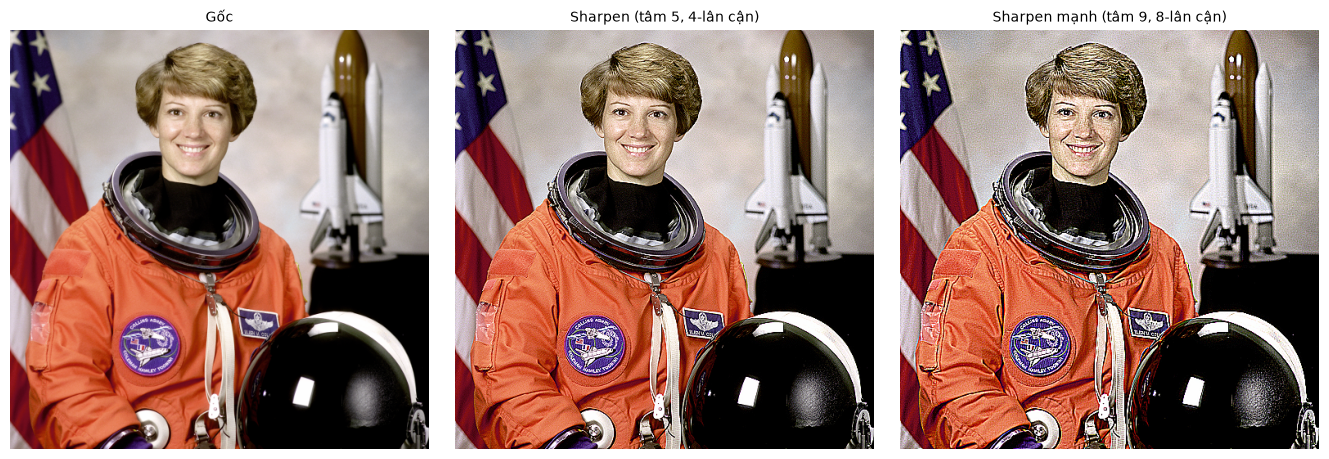

In [8]:
k_sharp  = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32)
k_sharp8 = np.array([[-1, -1, -1], [-1, 9, -1], [-1, -1, -1]], np.float32)
show([astro, cv2.filter2D(astro, -1, k_sharp), cv2.filter2D(astro, -1, k_sharp8)],
     ["Gốc", "Sharpen (tâm 5, 4-lân cận)", "Sharpen mạnh (tâm 9, 8-lân cận)"], cols=3, size=4.5)

# III. Bài tập nâng cao

## 8. Phát hiện cạnh: Sobel & Prewitt
Tính $G_x, G_y$ ở `float32` (giữ giá trị âm) rồi $M=\sqrt{G_x^2+G_y^2}$. Sobel dùng trọng số 1–2–1, Prewitt dùng 1–1–1.

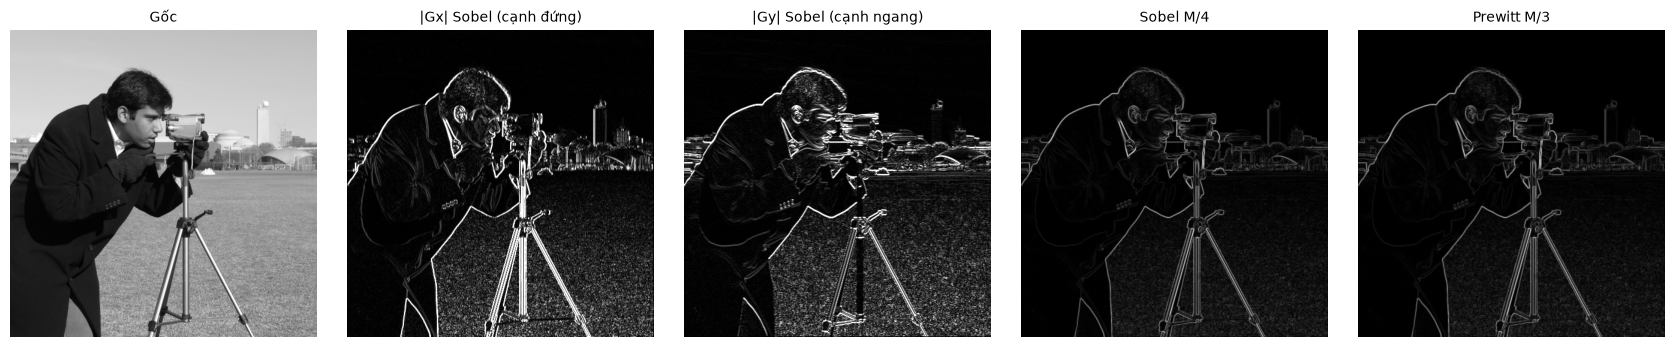

In [9]:
kx_prewitt = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)

def sobel(img):
    gx, gy = (cv2.Sobel(img, cv2.CV_32F, *d, ksize=3) for d in [(1, 0), (0, 1)])
    return gx, gy, np.hypot(gx, gy)

def prewitt(img):
    gx = cv2.filter2D(img, cv2.CV_32F, kx_prewitt)
    gy = cv2.filter2D(img, cv2.CV_32F, kx_prewitt.T)
    return gx, gy, np.hypot(gx, gy)

to_u8 = lambda m: np.clip(m, 0, 255).astype(np.uint8)
sx, sy, sm = sobel(cam); px_, py_, pm = prewitt(cam)
show([cam, to_u8(np.abs(sx)), to_u8(np.abs(sy)), to_u8(sm / 4), to_u8(pm / 3)],
     ["Gốc", "|Gx| Sobel (cạnh đứng)", "|Gy| Sobel (cạnh ngang)", "Sobel M/4", "Prewitt M/3"], cols=5, size=3.4)

## 9. Tự thiết kế kernel
Các kernel tùy chỉnh cho hiệu ứng khác nhau: cạnh ngang, cạnh đứng, cạnh mọi hướng (Laplacian), emboss, làm mờ chéo.

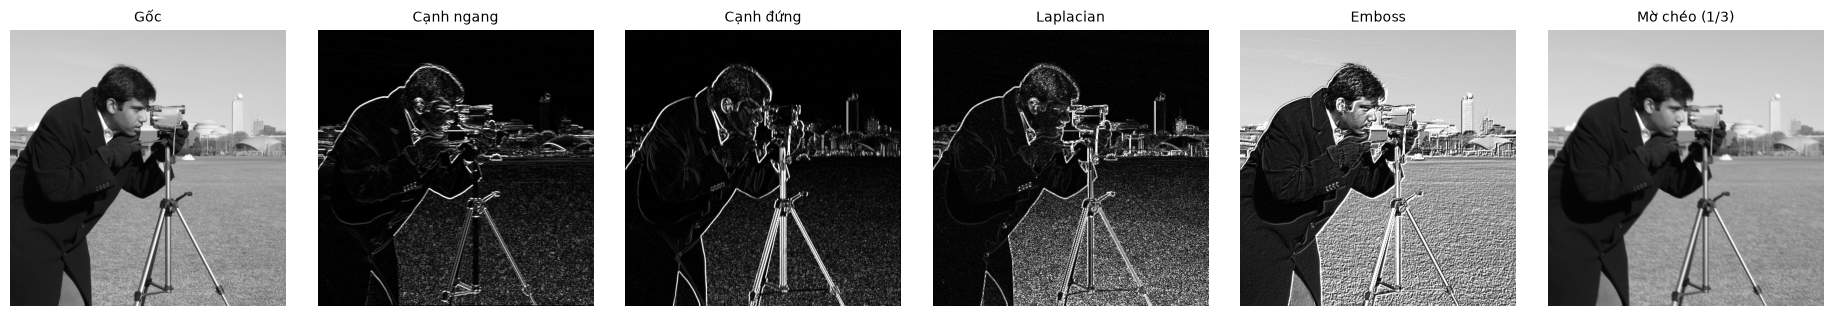

In [10]:
kernels = {
    "Cạnh ngang":     np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], np.float32),
    "Cạnh đứng":      np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32),
    "Laplacian":      np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], np.float32),
    "Emboss":         np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], np.float32),
    "Mờ chéo (1/3)":  np.eye(3, dtype=np.float32) / 3,
}
outs = [cv2.convertScaleAbs(cv2.filter2D(cam, cv2.CV_32F, k)) if "mờ" not in n.lower() else cv2.filter2D(cam, -1, k)
        for n, k in kernels.items()]
show([cam] + outs, ["Gốc"] + list(kernels), cols=6, size=3.1)

## 10. So sánh các loại lọc trên cùng một ảnh
Cùng ảnh `04_camera` + 2 loại nhiễu (Gaussian σ=20, muối tiêu 4%); đo PSNR/SSIM so với ảnh sạch và thời gian chạy.

In [11]:
def salt_pepper(img, p=0.04, seed=42):
    r = np.random.default_rng(seed).random(img.shape)
    out = img.copy(); out[r < p / 2] = 0; out[r > 1 - p / 2] = 255
    return out
noisy_sp = salt_pepper(cam)

filters = {
    "Mean 5×5":      lambda im: cv2.blur(im, (5, 5)),
    "Gaussian 5×5":  lambda im: cv2.GaussianBlur(im, (5, 5), 0),
    "Median 5×5":    lambda im: cv2.medianBlur(im, 5),
    "Bilateral":     lambda im: cv2.bilateralFilter(im, 9, 75, 75),
}
def avg_ms(f, im, n=20):
    t = time.perf_counter()
    for _ in range(n): f(im)
    return (time.perf_counter() - t) / n * 1000

rows = []
for name, f in filters.items():
    rows.append({"Bộ lọc": name,
                 "PSNR nhiễu Gauss": psnr(cam, f(noisy_g)), "SSIM nhiễu Gauss": ssim(cam, f(noisy_g)),
                 "PSNR muối tiêu": psnr(cam, f(noisy_sp)), "SSIM muối tiêu": ssim(cam, f(noisy_sp)),
                 "Thời gian (ms)": avg_ms(f, noisy_g)})
pd.DataFrame(rows).round(3).set_index("Bộ lọc")

,PSNR nhiễu Gauss,SSIM nhiễu Gauss,PSNR muối tiêu,SSIM muối tiêu,Thời gian (ms)
Bộ lọc,,,,,
Mean 5×5,26.175,0.687,25.464,0.615,0.461
Gaussian 5×5,27.838,0.702,26.283,0.612,0.098
Median 5×5,26.810,0.660,27.902,0.796,0.627
Bilateral,27.926,0.745,21.962,0.473,6.495


## 11. Lọc phi tuyến: Median & Bilateral
- **Median**: thay pixel bằng trung vị lân cận → loại nhiễu xung (muối tiêu) mà không tạo "đốm xám" như bộ lọc tuyến tính.
- **Bilateral**: trọng số theo cả khoảng cách không gian **và** chênh lệch cường độ → làm mịn nhưng giữ cạnh.

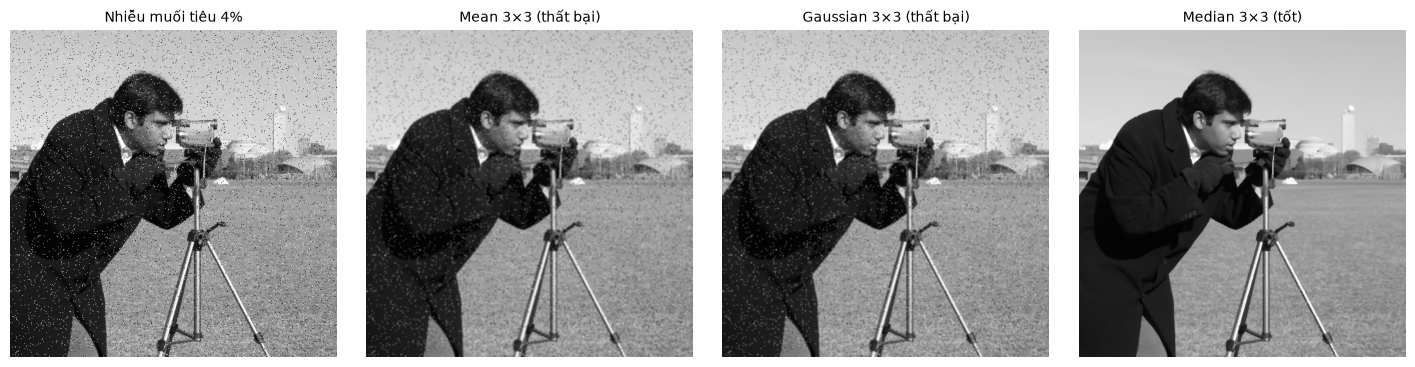

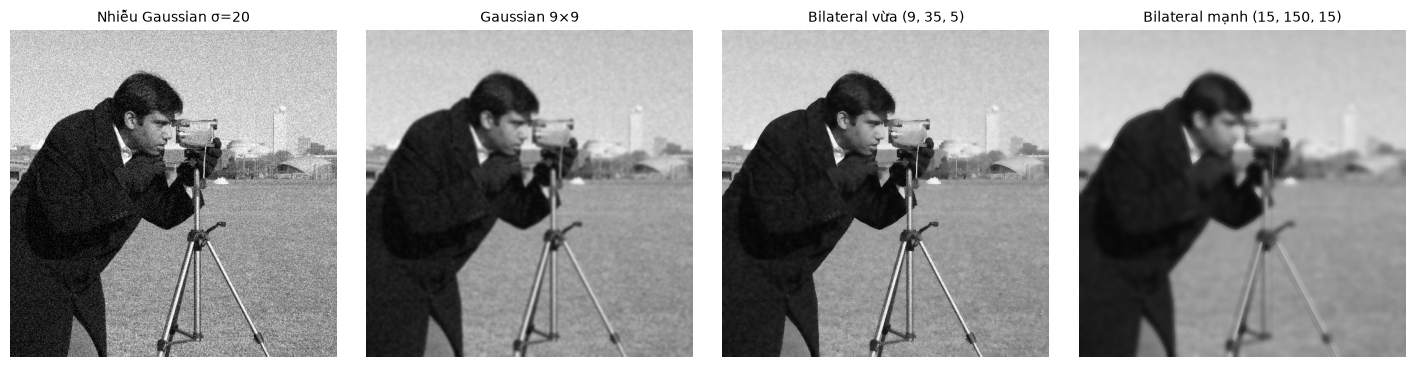

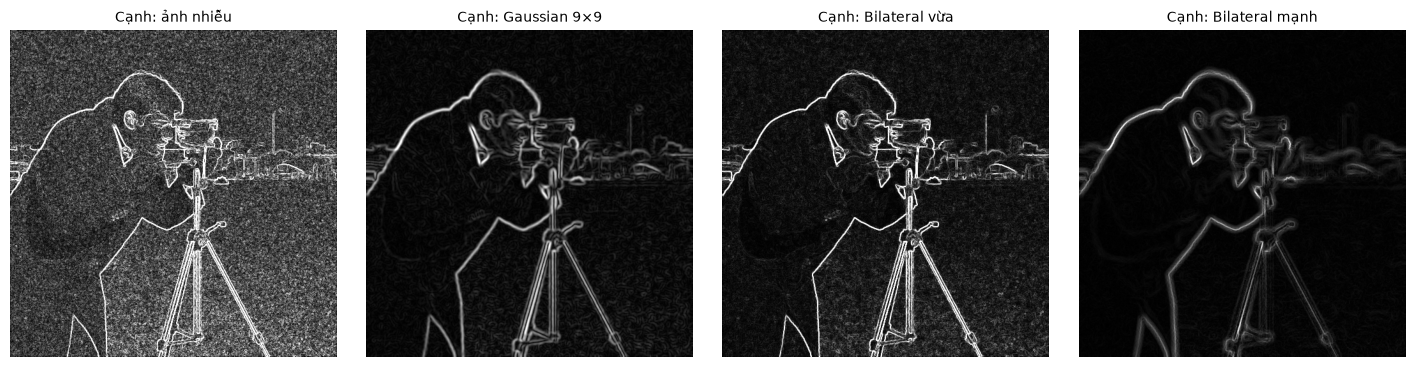

In [12]:
show([noisy_sp, cv2.blur(noisy_sp, (3, 3)), cv2.GaussianBlur(noisy_sp, (3, 3), 0), cv2.medianBlur(noisy_sp, 3)],
     ["Nhiễu muối tiêu 4%", "Mean 3×3 (thất bại)", "Gaussian 3×3 (thất bại)", "Median 3×3 (tốt)"])

show([noisy_g, cv2.GaussianBlur(noisy_g, (9, 9), 0), cv2.bilateralFilter(noisy_g, 9, 35, 5), cv2.bilateralFilter(noisy_g, 15, 150, 15)],
     ["Nhiễu Gaussian σ=20", "Gaussian 9×9", "Bilateral vừa (9, 35, 5)", "Bilateral mạnh (15, 150, 15)"])

# Cạnh sau lọc: Bilateral giữ cạnh hơn Gaussian nhưng tham số quá mạnh sẽ xóa cả chi tiết nhỏ
edge = lambda im: to_u8(sobel(im)[2] / 4 * 3)
show([edge(noisy_g), edge(cv2.GaussianBlur(noisy_g, (9, 9), 0)), edge(cv2.bilateralFilter(noisy_g, 9, 35, 5)), edge(cv2.bilateralFilter(noisy_g, 15, 150, 15))],
     ["Cạnh: ảnh nhiễu", "Cạnh: Gaussian 9×9", "Cạnh: Bilateral vừa", "Cạnh: Bilateral mạnh"])

# Kết luận

| Yêu cầu | Kết quả chính |
|---|---|
| **Độ sáng** | Cộng/trừ β làm cả ảnh sáng/tối hơn; β lớn gây *clipping* (250+30 → 255), mất chi tiết vùng quá sáng/tối. |
| **Tương phản** | α<1 kéo các mức xám về giữa (ảnh nhạt), α>1 đẩy sáng→sáng hơn, tối→tối hơn; α=2 clip nhiều. |
| **Âm bản** | $s=255-r$ đảo ngược hoàn toàn, không mất thông tin; hữu ích để quan sát chi tiết vùng tối. |
| **Cắt ngưỡng** | T nhỏ → nhiều vùng trắng, T lớn → chỉ còn vùng sáng nhất. Ngưỡng toàn cục tách tốt `coins` (Otsu) nhưng kém trên `page` do ánh sáng không đều. |
| **Mean** | Đơn giản, nhanh, nhưng làm nhòe cạnh mạnh khi kernel lớn. Tích chập tự cài đặt khớp `cv2` (sai khác = 0). |
| **Gaussian** | Trọng số giảm theo khoảng cách → mờ tự nhiên, giữ cấu trúc tốt hơn Mean (nhiễu Gauss: PSNR 28.0 dB vs 27.4 dB ở 3×3; SSIM 0.702 vs 0.687 ở 5×5). |
| **Sắc nét** | Tâm dương + lân cận âm làm nổi cạnh; kernel càng mạnh càng khuếch đại nhiễu. |
| **Sobel/Prewitt** | Cùng phát hiện cạnh từ $G_x,G_y$; Sobel nhấn mạnh hàng/cột giữa (1-2-1), Prewitt trọng số đều. Cả hai nhạy với nhiễu → nên lọc trước. |
| **Kernel tự thiết kế** | Đổi hệ số kernel → các hiệu ứng khác nhau (cạnh ngang/đứng, Laplacian, emboss, mờ chéo). |
| **So sánh bộ lọc** | Nhiễu Gauss: Gaussian đạt PSNR cao nhất trong nhóm tuyến tính, Bilateral có SSIM cao nhất (0.745). Nhiễu muối tiêu: **Median** thắng rõ (PSNR 27.9 dB, SSIM 0.796), Mean/Gaussian chỉ làm "loang" nhiễu. |
| **Phi tuyến** | Median xử lý nhiễu xung và giữ cạnh; Bilateral giữ cạnh tốt khi nhiễu Gauss nhưng **chậm nhất** (~8 ms vs <0.5 ms) và kém với muối tiêu (các điểm nhiễu bị coi là cạnh). Tham số quá mạnh sẽ xóa cả cạnh yếu. |

**Chọn bộ lọc theo bài toán:** nhiễu Gauss → Gaussian (nhanh) hoặc Bilateral (giữ cạnh); nhiễu muối tiêu → Median; cần nổi cạnh → Sharpen / Sobel (sau khi khử nhiễu). Không có bộ lọc nào tốt nhất cho mọi loại ảnh.